# Week 09 - AgentFlow

Qwen2.5-7B-Instruct plans tool use, executes actions, verifies the evidence and generates final answers. Run this notebook locally; Qwen inference runs on Modal.
The module instructions follow Appendix E.1, with interface adaptations described in [agent_flow/README.md](agent_flow/README.md#paper-settings-and-implementation-choices).


## 1. Local dependencies

Install the libraries below in your Jupyter environment. API setup and file responsibilities are described in [agent_flow/README.md](agent_flow/README.md).

In [1]:
%pip install modal==1.6.4 pandas==2.2.3 matplotlib==3.10.1 python-dotenv

Note: you may need to restart the kernel to use updated packages.


## 2. Configuration

Run three trials with seeds 42, 43 and 44. Each trial answers the same 125 questions, producing 125 final answers per trial and 375 in total. Each question can use up to ten tool-interaction rounds, ending early when the verifier decides the evidence is sufficient.

In [2]:
from pathlib import Path
import os
import sys

MODAL_PROFILE = "neu-info5100-oak-spr-2025"
GPU = "A100-80GB"
RUN_NAME = "qwen7b-agentflow-paper-prompts-v1"
QUESTION_LIMIT = 125
MODEL_REVISION = "a09a35458c702b33eeacc393d103063234e8bc28"
TRIAL_SEEDS = [42, 43, 44]
BATCH_SIZE = 32
MAX_TURNS = 10
TEMPERATURE = 0.7
PLANNER_MAX_NEW_TOKENS = 2048
MODULE_MAX_NEW_TOKENS = 512
MAX_NEW_TOKENS = 512
SEARCH_MODEL = "gpt-5.4-mini"
EMBEDDING_MODEL = "text-embedding-3-small"
CHUNK_WORDS = 200
CHUNK_OVERLAP_WORDS = 20
RETRIEVAL_TOP_K = 10
PAGE_MAX_WORDS = 1_000_000
JUDGE_MODEL = "gpt-4o-2024-08-06"
RUN_INFERENCE = True
RUN_JUDGE = True

os.environ["MODAL_PROFILE"] = MODAL_PROFILE
HERE = Path.cwd()
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))

import pandas as pd
from IPython.display import display, Markdown
from baseline import evaluation as ev
from agent_flow import results

benchmark = results.load_benchmark(HERE / "bamboogle.json")
questions = benchmark["rows"][:QUESTION_LIMIT]
SETTINGS = dict(question_limit=QUESTION_LIMIT, seeds=TRIAL_SEEDS,
                model_revision=MODEL_REVISION, gpu=GPU, batch_size=BATCH_SIZE,
                max_turns=MAX_TURNS, temperature=TEMPERATURE,
                planner_max_new_tokens=PLANNER_MAX_NEW_TOKENS,
                module_max_new_tokens=MODULE_MAX_NEW_TOKENS, max_new_tokens=MAX_NEW_TOKENS,
                search_model=SEARCH_MODEL, embedding_model=EMBEDDING_MODEL,
                chunk_words=CHUNK_WORDS, chunk_overlap_words=CHUNK_OVERLAP_WORDS,
                retrieval_top_k=RETRIEVAL_TOP_K, page_max_words=PAGE_MAX_WORDS,
                judge_model=JUDGE_MODEL)
OUTPUT_ROOT = HERE / "outputs"
RUN_DIR = OUTPUT_ROOT / RUN_NAME
print("Local result directory:", RUN_DIR)

Local result directory: /mnt/c/Users/flywi/Desktop/gitRepos/neu-self-improve-ai/week_09/outputs/qwen7b-agentflow-paper-prompts-v1


## 3. Sequential AgentFlow inference

Load Qwen once and run the three trials in order. The planner, executor and verifier share the interaction history for each question. The solution generator reads that history to produce the final answer. Put `OPENAI_API_KEY` in `.env` before inference.

In [3]:
if not RUN_INFERENCE:
    manifest = results.read_json(RUN_DIR / "manifest.json")
    saved = results.read_json(RUN_DIR / "sequential_response.json")
    records = results.response_records(saved)
    print("Using saved answers.")
else:
    import time
    import modal
    from dotenv import dotenv_values

    credentials = dotenv_values(HERE / ".env", encoding="utf-8-sig")
    api_keys = {"OPENAI_API_KEY": credentials.get("OPENAI_API_KEY")}
    del credentials
    if not all(api_keys.values()):
        raise ValueError("Set OPENAI_API_KEY in .env before inference.")
    tool_secret = modal.Secret.from_dict(api_keys)
    del api_keys
    RUN_DIR, manifest = results.prepare_run(OUTPUT_ROOT, RUN_NAME, SETTINGS)
    from agent_flow.modal_app import app, answer_trials

    display(Markdown(f"**Running {len(TRIAL_SEEDS)} sequential AgentFlow trials on one {GPU}.**"))
    started = time.perf_counter()
    with app.run():
        output = answer_trials.with_options(gpu=GPU, secrets=[tool_secret]).remote(
            [q["question"] for q in questions], SETTINGS)
    saved = {"client_call_seconds": time.perf_counter() - started, "output": output}
    saved = results.prepare_response(saved, manifest, questions)
    records = results.response_records(saved)
    total = len(questions) * len(TRIAL_SEEDS)
    if len(records) != total:
        raise RuntimeError("Inference returned an incomplete set of answers.")
    results.write_json(RUN_DIR / "sequential_response.json", saved)
    display(Markdown(f"**Inference complete:** {len(records)}/{total} final answers saved locally."))
    display(pd.DataFrame(records)[["trial", "seed", "question", "response"]].tail(5))

**Running 3 sequential AgentFlow trials on one A100-80GB.**

**Inference complete:** 375/375 final answers saved locally.

,trial,seed,question,response
370,3,44,When was the composer of Carol of the Bells born?,Process Summary:\n1. The Wikipedia Search tool...
371,3,44,Who is the father of the scientist at MIT that...,"Process Summary:\n1. Initially, a web search w..."
372,3,44,Who was the mother of the emperor of Japan dur...,Process Summary: \n1. The initial attempts to ...
373,3,44,Which element has an atomic number that is dou...,Process Summary:\n1. Determined the atomic num...
374,3,44,What was the motto of the Olympics that had Fu...,Process Summary:\n1. To identify the Olympics ...


In [4]:
timing = saved["output"]
print("Actual GPU:", timing["gpu"])
display(pd.DataFrame([{
    "trial": trial["trial"], "seed": trial["seed"],
    "trial_seconds": trial["trial_seconds"],
    "generation_seconds": trial["generation_seconds"],
    "mean_rounds": sum(len(a["trajectory"]) for a in trial["responses"]) / len(trial["responses"]),
    "peak_gpu_reserved_GiB": trial["peak_gpu_reserved_gib"],
} for trial in timing["outputs"]]))

Actual GPU: NVIDIA A100-SXM4-80GB


,trial,seed,trial_seconds,generation_seconds,mean_rounds,peak_gpu_reserved_GiB
0,1,42,2731.136907,2246.644427,6.464,78.261719
1,2,43,2228.961202,1752.157874,5.760,77.769531
2,3,44,2468.991769,2078.373129,6.096,78.583984


## 4. GPT-4o scoring

Set `RUN_JUDGE=True` to score the final answers using `OPENAI_API_KEY` from `.env`. GPT-4o checks whether each final answer is equivalent to a reference answer and returns a correctness decision with a brief explanation.
The scoring instructions follow Appendix E.3, with JSON output and support for alternative reference answers. Each request uses the instructions saved in the run manifest.


In [5]:
if not RUN_JUDGE:
    print("Judging is off. Set RUN_JUDGE=True in configuration when ready.")
else:
    from dotenv import dotenv_values
    pending = [r for r in records if r.get("judge") is None]
    if pending:
        api_key = dotenv_values(HERE / ".env", encoding="utf-8-sig").get("OPENAI_API_KEY")
        judged = len(records) - len(pending)
        judge_status = display(Markdown(f"**Grading progress:** {judged}/{len(records)} answers graded."), display_id=True)
        judge_preview = display(pd.DataFrame(columns=["question_id", "correct", "analysis"]), display_id=True)
        try:
            for record in pending:
                record["judge"] = ev.judge_answer(
                    record["question"], record["reference_answers"], record["response"],
                    manifest["protocol"]["settings"]["judge_model"], api_key,
                    prompt=manifest["protocol"]["judge_prompt"])
                results.save_judgment(RUN_DIR, record["trial"], record["question_id"], record["judge"])
                judged += 1
                judge_status.update(Markdown(f"**Grading progress:** {judged}/{len(records)} grading results saved."))
                judge_preview.update(pd.DataFrame([{
                    "question_id": record["question_id"], "correct": record["judge"]["correct"],
                    "analysis": record["judge"]["analysis"]}]))
        finally:
            del api_key
            records = results.load_records(RUN_DIR)
    else:
        print("All saved responses have already been judged; no API requests made.")

**Grading progress:** 375/375 grading results saved.

,question_id,correct,analysis
0,bamboogle-125,True,The final answer extracted from the Model Resp...


## 5. Trial results and accuracy

Report the correct-answer count and accuracy for each completed trial. The mean is the arithmetic mean of the three accuracies; the sample standard deviation is expressed in percentage points.

### AgentFlow - Qwen2.5-7B-Instruct

Benchmark scope: full_125
Model revision: a09a35458c702b33eeacc393d103063234e8bc28
Saved responses: 375 | length-limited: 0


,trial,seed,expected,generated,judged,correct,accuracy_percent,status
0,1,42,125,125,125,49,39.2,complete
1,2,43,125,125,125,59,47.2,complete
2,3,44,125,125,125,51,40.8,complete


**Mean accuracy: 42.40%** · sample standard deviation: 4.23 percentage points

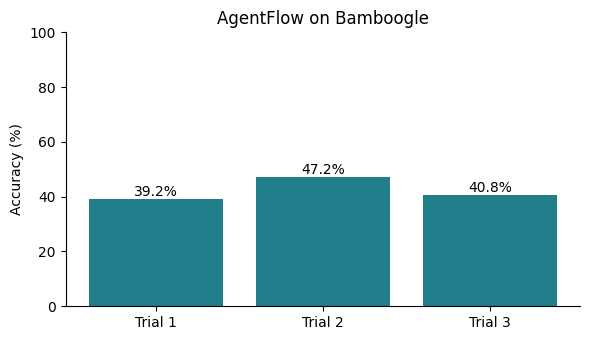

In [6]:
report = ev.summary(records, manifest)
display(Markdown("### AgentFlow - Qwen2.5-7B-Instruct"))
print("Benchmark scope:", report["benchmark_scope"])
print("Model revision:", report["model_revision"])
print("Saved responses:", len(records), "| length-limited:", report["length_limited_responses"])
trial_table = pd.DataFrame(report["trials"])
display(trial_table)
if report["complete"]:
    mean = report["mean_accuracy_percent"]
    std = report["sample_std_percentage_points"]
    message = f"**Mean accuracy: {mean:.2f}%**"
    if std is not None:
        message += f" · sample standard deviation: {std:.2f} percentage points"
    display(Markdown(message))
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.bar([f"Trial {t}" for t in trial_table.trial], trial_table.accuracy_percent, color="#237e8c")
    ax.set(ylabel="Accuracy (%)", ylim=(0, 100), title="AgentFlow on Bamboogle")
    ax.spines[["top", "right"]].set_visible(False)
    for i, value in enumerate(trial_table.accuracy_percent):
        ax.text(i, value + 1, f"{value:.1f}%", ha="center")
    fig.tight_layout()
    plt.show()
else:
    display(Markdown("**Evaluation is incomplete. Overall accuracy is not yet reported.**"))

## Saved files

Paths are relative to the notebook folder. `<RUN_NAME>` is the configured run name.

| Relative path | Contents |
| --- | --- |
| `outputs/<RUN_NAME>/manifest.json` | Model identity, initial settings, module instructions, tool descriptions and grading instructions. |
| `outputs/<RUN_NAME>/sequential_response.json` | Three trial groups. Each trial contains its seed, timings, Qwen token totals, peak reserved GPU memory and 125 answer records. Each answer record contains the question, reference answers, generated final answer, interaction history and grading result. Actual GPU information, library versions and overall timings are stored once outside the trial groups. |

The `trajectory` in each answer records the plans, tool calls, tool results and verifier conclusions. Scoring reads the questions, reference answers and final answers from `outputs/<RUN_NAME>/sequential_response.json`, then saves each decision in the corresponding answer's `judge` field. Accuracy is calculated from those decisions without creating another result file.